# TPOD — Finansal Dolandırıcılık Benchmark'ı (Metodolojik Protokol)

Bu notebook, `TPOD_Fraud_Detection.ipynb`'deki ilk deneyin metodolojik zayıflıklarını gidermek için hazırlanmıştır. İlk deney **değiştirilmeden** korunmuştur.

| Konu | İlk deney | Bu benchmark |
|---|---|---|
| Fraud oranı | ~%33 | **%1, %2, %5** (gerçekçi) |
| Tekrar | 1 örneklem | **10 bağımsız örneklem**, ortalama ± std |
| Parametre seçimi | Test etiketleri üzerinde grid search (sızıntı) | **Sabit**: c = 0.5, η kontaminasyon oranından |
| Karşılaştırma | Yok | **LOF, Isolation Forest, kNN, COF, ABOD** + RF (gözetimli üst sınır) |
| Metrikler | AUC, F1 | **AUC, AUPRC, P@n**, F1 |
| İstatistik | Yok | **Friedman + Wilcoxon (Holm düzeltmeli)** |

**Adil karşılaştırma ilkesi:** Tüm gözetimsiz algoritmalar etiket görmez, PyOD varsayılan parametreleriyle çalışır; hepsine yalnızca bilinen kontaminasyon oranı verilir.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings, os, glob, time
warnings.filterwarnings("ignore")

from scipy.spatial.distance import cdist
from scipy.stats import friedmanchisquare, wilcoxon
from sklearn.neighbors import KDTree
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from pyod.models.lof import LOF
from pyod.models.iforest import IForest
from pyod.models.knn import KNN
from pyod.models.cof import COF
from pyod.models.abod import ABOD

print("Kutuphaneler yuklendi")

Kutuphaneler yuklendi


## 1. TPOD — Vektörleştirilmiş İmplementasyon

Algoritma mantığı (Algorithm 1 + 2, Formül 10–16) **birebir aynıdır**; yalnızca Python döngüleri NumPy matris işlemleriyle değiştirilmiştir. Orijinal implementasyonla aynı λ, aynı etiketleri ve ~1e-15 göreli farkla aynı skorları ürettiği doğrulanmıştır.

**η'nın kontaminasyondan belirlenmesi:** Formül 16'daki eşik σ = η·mean(TPOD). Beklenen fraud oranı p biliniyorsa σ, skorların (1−p) yüzdeliği olarak seçilir; buradan η = σ / mean(TPOD) elde edilir. Böylece etiket kullanılmadan η belirlenir.

In [2]:
def natural_neighbors(X):
    """Algorithm 1: Natural Neighbor Search (np.bincount ile)"""
    n = len(X)
    tree = KDTree(X)
    k = 1
    prev_zero_count = -1
    while True:
        _, knn_idx = tree.query(X, k=k + 1)
        knn_idx = knn_idx[:, 1:]
        nb = np.bincount(knn_idx.ravel(), minlength=n)
        zero_count = int(np.sum(nb == 0))
        if zero_count == 0 or zero_count == prev_zero_count:
            break
        prev_zero_count = zero_count
        k += 1
    return k, knn_idx


def tpod_scores(X, c=0.5, eps=1e-5):
    """Algorithm 2: TPOD skorlari (vektorlestirilmis). Doner: scores, lambda"""
    lam, idx = natural_neighbors(X)
    D  = cdist(X, X)
    dn = np.take_along_axis(D, idx, axis=1)          # dogal komsulara uzakliklar

    # Formul 10: adaptif kernel genisligi
    d_lambda = dn.mean(axis=1)
    h = np.maximum(c * (d_lambda.max() + d_lambda.min() + eps - d_lambda), eps)

    # Formul 11: yerel yogunluk (Gaussian kernel)
    sq = D ** 2
    np.fill_diagonal(sq, np.inf)
    rho = np.exp(-sq / (h[:, None] ** 2 + eps)).mean(axis=1)

    # Formul 12-14: goreli mesafe
    d_bar = dn.mean(axis=1)
    L = idx.shape[1]
    if L < 2:
        D_bar = d_bar + eps
    else:
        sub = D[idx[:, :, None], idx[:, None, :]]
        iu  = np.triu_indices(L, 1)
        D_bar = sub[:, iu[0], iu[1]].mean(axis=1)
    RD = d_bar / (D_bar + eps)

    # Formul 15
    return RD / (rho + eps), lam


def eta_from_contamination(scores, contamination):
    """Formul 16 icin eta: sigma = (1-p) yuzdeligi, eta = sigma / mean"""
    sigma = np.quantile(scores, 1 - contamination)
    return sigma / np.mean(scores)


print("TPOD hazir")

TPOD hazir


## 2. Veri Setleri — Tam Veri Yükleme

Her veri seti bir kez tamamen yüklenir; her tekrar için bu havuzdan farklı rastgele örneklem çekilir. Özellik seçimi ilk deneyle aynıdır.

In [3]:
DATA_ROOT = ".."  # veri setleri ust klasorde

def find_file(name):
    hits = glob.glob(os.path.join(DATA_ROOT, "**", name), recursive=True)
    if not hits:
        raise FileNotFoundError(name + " bulunamadi")
    return hits[0]


def load_ulb():
    df = pd.read_csv(find_file("creditcard.csv"))
    feats = [c for c in df.columns if c not in ("Time", "Class")]
    return df[feats].values.astype(float), df["Class"].values.astype(int)


def load_paysim():
    cols = ["type","amount","oldbalanceOrg","newbalanceOrig",
            "oldbalanceDest","newbalanceDest","isFraud"]
    df = pd.read_csv(find_file("PS_*log*.csv"), usecols=cols)
    df = df[df["type"].isin(["TRANSFER","CASH_OUT"])]
    df["type"] = (df["type"] == "TRANSFER").astype(int)
    return df[cols[:-1]].values.astype(float), df["isFraud"].values.astype(int)


def load_baf():
    df = pd.read_csv(find_file("Base.csv"))
    for col in df.select_dtypes(include=["object"]).columns:
        df[col] = LabelEncoder().fit_transform(df[col].astype(str))
    feats = [c for c in df.columns if c != "fraud_bool"]
    return df[feats].values.astype(float), df["fraud_bool"].values.astype(int)


def load_sparkov():
    df = pd.read_csv(find_file("fraudTrain.csv"))
    t = pd.to_datetime(df["trans_date_trans_time"])
    df["hour"] = t.dt.hour
    df["age"]  = (t - pd.to_datetime(df["dob"])).dt.days / 365.25
    df["dist"] = np.sqrt((df["lat"] - df["merch_lat"])**2 + (df["long"] - df["merch_long"])**2)
    df["category_enc"] = LabelEncoder().fit_transform(df["category"].astype(str))
    df["gender_enc"]   = (df["gender"] == "M").astype(int)
    feats = ["amt","category_enc","gender_enc","city_pop","hour","age","dist","lat","long"]
    return df[feats].values.astype(float), df["is_fraud"].values.astype(int)


LOADERS = {"ULB": load_ulb, "PaySim": load_paysim, "BAF": load_baf, "Sparkov": load_sparkov}
POOLS = {}
for name, fn in LOADERS.items():
    t0 = time.time()
    X, y = fn()
    POOLS[name] = (X, y)
    print(name.ljust(8) + " shape=" + str(X.shape) + "  fraud=" + str(y.sum()) +
          " (" + f"{y.mean()*100:.3f}" + "%)  " + f"{time.time()-t0:.1f}" + "s")

ULB      shape=(284807, 29)  fraud=492 (0.173%)  0.9s


PaySim   shape=(2770409, 6)  fraud=8213 (0.296%)  3.4s


BAF      shape=(1000000, 31)  fraud=11029 (1.103%)  2.4s


Sparkov  shape=(1048575, 9)  fraud=6006 (0.573%)  44.0s


## 3. Deney Konfigürasyonu

In [4]:
N_SAMPLE = 2000                 # her ornekleme toplam kayit
RATIOS   = [0.01, 0.02, 0.05]   # gercekci fraud oranlari
N_REPS   = 10                   # bagimsiz tekrar sayisi
C_TPOD   = 0.5                  # makale araligi [0.5, 1.0]; v3'te tum veri setlerinde optimal

UNSUP = ["TPOD", "LOF", "IForest", "kNN", "COF", "ABOD"]
ALL_ALGOS = UNSUP + ["RF (gozetimli)"]


def draw_sample(X, y, ratio, seed):
    rng = np.random.default_rng(seed)
    n_f = int(round(N_SAMPLE * ratio))
    fi = rng.choice(np.where(y == 1)[0], n_f, replace=False)
    ni = rng.choice(np.where(y == 0)[0], N_SAMPLE - n_f, replace=False)
    idx = rng.permutation(np.concatenate([fi, ni]))
    return MinMaxScaler().fit_transform(X[idx]), y[idx]


def precision_at_n(y, s):
    n = int(y.sum())
    top = np.argsort(-s)[:n]
    return y[top].mean()


def run_algo(name, X, y, ratio, seed):
    """Doner: skorlar (buyuk = daha aykiri), ikili etiketler"""
    if name == "TPOD":
        s, _ = tpod_scores(X, c=C_TPOD)
        eta = eta_from_contamination(s, ratio)
        return s, (s > eta * s.mean()).astype(int)
    if name == "RF (gozetimli)":
        cv = StratifiedKFold(5, shuffle=True, random_state=seed)
        rf = RandomForestClassifier(300, n_jobs=-1, random_state=seed, class_weight="balanced")
        s = cross_val_predict(rf, X, y, cv=cv, method="predict_proba")[:, 1]
        return s, (s >= np.quantile(s, 1 - ratio)).astype(int)
    model = {"LOF": LOF(contamination=ratio),
             "IForest": IForest(contamination=ratio, random_state=seed),
             "kNN": KNN(contamination=ratio),
             "COF": COF(contamination=ratio),
             "ABOD": ABOD(contamination=ratio)}[name]
    model.fit(X)
    return model.decision_scores_, model.labels_


print("Toplam calisma: " + str(len(POOLS) * len(RATIOS) * N_REPS * len(ALL_ALGOS)))

Toplam calisma: 840


## 4. Benchmark Çalıştırma

Sonuçlar `tpod_benchmark_results.csv` dosyasına kaydedilir; dosya varsa yeniden hesaplanmaz (silerek yeniden çalıştırabilirsiniz).

In [5]:
RESULTS_CSV = "tpod_benchmark_results.csv"

if os.path.exists(RESULTS_CSV):
    res = pd.read_csv(RESULTS_CSV)
    print("Onceki sonuclar yuklendi: " + str(len(res)) + " satir")
else:
    rows = []
    t_start = time.time()
    for ds, (Xp, yp) in POOLS.items():
        for ratio in RATIOS:
            for rep in range(N_REPS):
                X, y = draw_sample(Xp, yp, ratio, seed=rep)
                for algo in ALL_ALGOS:
                    t0 = time.time()
                    try:
                        s, lab = run_algo(algo, X, y, ratio, rep)
                        s = np.nan_to_num(s, nan=0.0, posinf=np.finfo(float).max)
                        rows.append({"dataset": ds, "ratio": ratio, "rep": rep, "algo": algo,
                                     "AUC": roc_auc_score(y, s),
                                     "AUPRC": average_precision_score(y, s),
                                     "P@n": precision_at_n(y, s),
                                     "F1": f1_score(y, lab, zero_division=0),
                                     "time": time.time() - t0})
                    except Exception as e:
                        print("  HATA " + ds + " " + algo + ": " + str(e))
            print(ds + " %" + str(int(ratio*100)) + " tamam  (" +
                  f"{(time.time()-t_start)/60:.1f}" + " dk)")
    res = pd.DataFrame(rows)
    res.to_csv(RESULTS_CSV, index=False)
    print("Kaydedildi: " + RESULTS_CSV)

ULB %1 tamam  (0.8 dk)


ULB %2 tamam  (1.5 dk)


ULB %5 tamam  (2.3 dk)


PaySim %1 tamam  (2.8 dk)


PaySim %2 tamam  (3.2 dk)


...

BAF %2 tamam  (5.2 dk)


BAF %5 tamam  (6.0 dk)


Sparkov %1 tamam  (6.5 dk)


Sparkov %2 tamam  (7.0 dk)


Sparkov %5 tamam  (7.5 dk)
Kaydedildi: tpod_benchmark_results.csv


## 5. Sonuç Tabloları (ortalama ± std, 10 tekrar)

In [6]:
def table(metric):
    g = res.groupby(["dataset", "ratio", "algo"])[metric]
    m, s = g.mean().unstack(), g.std().unstack()
    out = m.round(3).astype(str) + " ± " + s.round(3).astype(str)
    return out[ALL_ALGOS], m[ALL_ALGOS]

tables = {}
for metric in ["AUC", "AUPRC", "P@n", "F1"]:
    txt, mean = table(metric)
    tables[metric] = mean
    print("=" * 30 + " " + metric + " " + "=" * 30)
    print(txt.to_string())
    print()

with pd.ExcelWriter("tpod_benchmark_tablolar.xlsx") as w:
    for metric in tables:
        table(metric)[0].to_excel(w, sheet_name=metric.replace("@", "at"))
print("Kaydedildi: tpod_benchmark_tablolar.xlsx")

============================== AUC ==============================
algo                    TPOD            LOF        IForest            kNN            COF           ABOD RF (gozetimli)
dataset ratio                                                                                                         
BAF     0.01   0.538 ± 0.044  0.579 ± 0.058   0.566 ± 0.05   0.53 ± 0.055  0.544 ± 0.065  0.523 ± 0.047  0.737 ± 0.071
        0.02   0.533 ± 0.041   0.583 ± 0.04  0.568 ± 0.029   0.52 ± 0.041  0.526 ± 0.032  0.523 ± 0.041   0.797 ± 0.04
        0.05   0.545 ± 0.023  0.585 ± 0.039  0.565 ± 0.039  0.538 ± 0.024  0.551 ± 0.037  0.543 ± 0.029   0.84 ± 0.024
PaySim  0.01   0.876 ± 0.025   0.88 ± 0.057  0.873 ± 0.039  0.848 ± 0.056   0.83 ± 0.048  0.818 ± 0.078  0.947 ± 0.037
        0.02   0.823 ± 0.047  0.886 ± 0.032  0.847 ± 0.021  0.821 ± 0.033  0.796 ± 0.061  0.761 ± 0.054  0.958 ± 0.024
        0.05   0.765 ± 0.028  0.823 ± 0.031  0.816 ± 0.021  0.735 ± 0.041  0.639 ± 0.047  0.634 ± 0.0

Kaydedildi: tpod_benchmark_tablolar.xlsx


## 6. Görselleştirme — Fraud Oranına Göre Performans

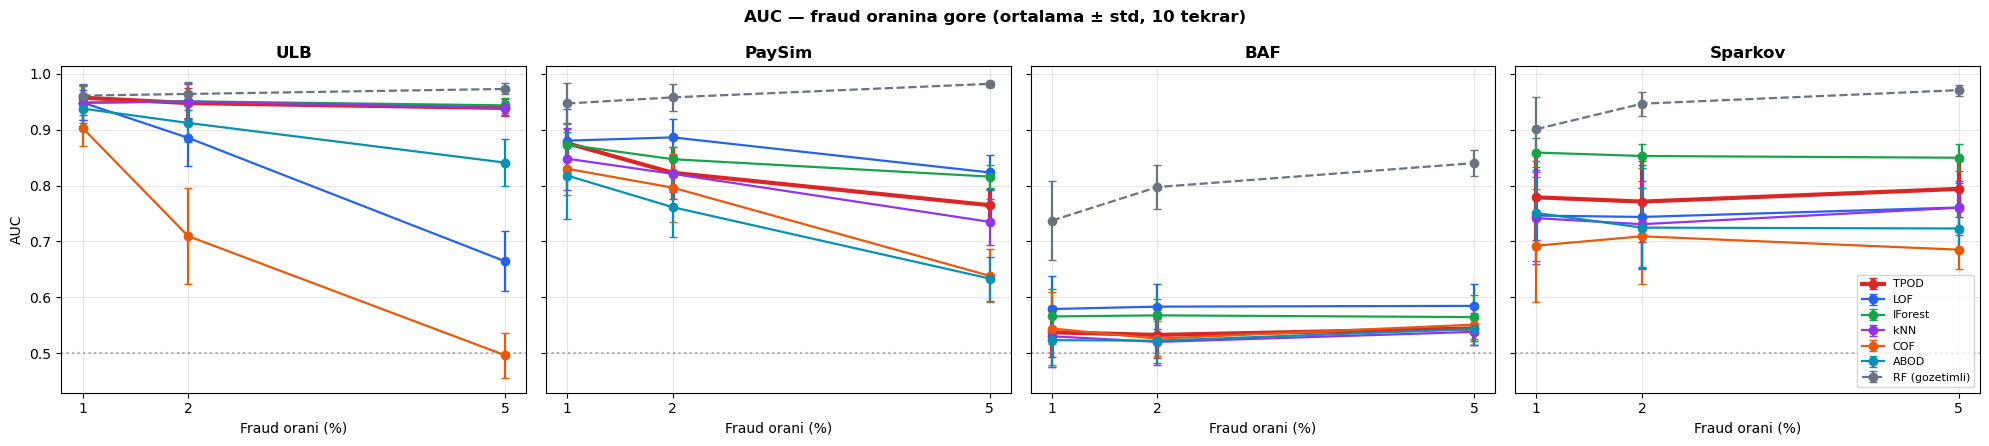

Kaydedildi: tpod_bench_auc.png


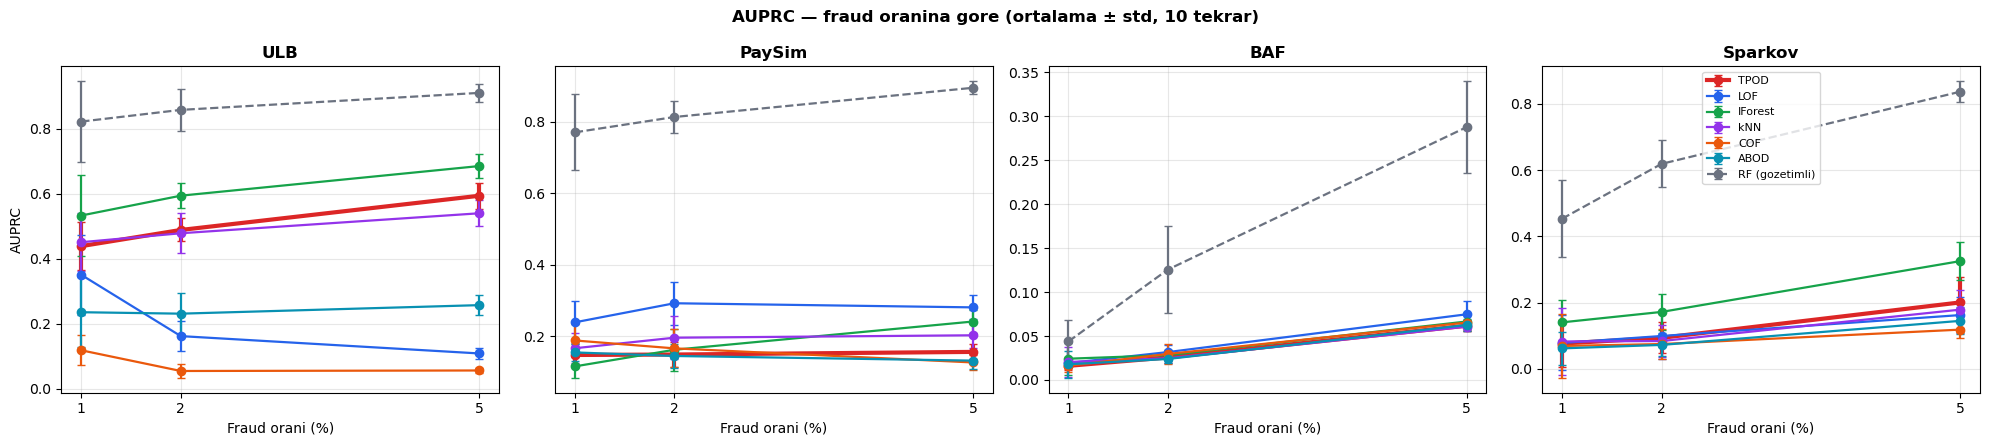

Kaydedildi: tpod_bench_auprc.png


In [7]:
colors = {"TPOD": "#DC2626", "LOF": "#2563EB", "IForest": "#16A34A", "kNN": "#9333EA",
          "COF": "#EA580C", "ABOD": "#0891B2", "RF (gozetimli)": "#6B7280"}
ds_list = list(POOLS.keys())

for metric in ["AUC", "AUPRC"]:
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharey=(metric == "AUC"))
    for ax, ds in zip(axes, ds_list):
        sub = res[res.dataset == ds]
        for algo in ALL_ALGOS:
            g = sub[sub.algo == algo].groupby("ratio")[metric]
            m, s = g.mean(), g.std()
            ls = "--" if algo.startswith("RF") else "-"
            lw = 3 if algo == "TPOD" else 1.6
            ax.errorbar(m.index * 100, m.values, yerr=s.values, label=algo, color=colors[algo],
                        linestyle=ls, linewidth=lw, marker="o", capsize=3)
        if metric == "AUC":
            ax.axhline(0.5, color="gray", linestyle=":", alpha=0.6)
        ax.set_title(ds, fontweight="bold")
        ax.set_xlabel("Fraud orani (%)")
        ax.set_xticks([1, 2, 5])
        ax.grid(alpha=0.3)
    axes[0].set_ylabel(metric)
    axes[-1].legend(fontsize=8, loc="best")
    plt.suptitle(metric + " — fraud oranina gore (ortalama ± std, 10 tekrar)", fontweight="bold")
    plt.tight_layout()
    fname = "tpod_bench_" + metric.lower() + ".png"
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()
    print("Kaydedildi: " + fname)

## 7. İstatistiksel Analiz

Her (veri seti, oran) kombinasyonu bir blok kabul edilir (4 × 3 = 12 blok). Blok içinde 10 tekrarın ortalaması alınır, algoritmalar sıralanır (1 = en iyi). Gözetimli RF bu analizde yer almaz.

- **Friedman testi:** Algoritmalar arasında anlamlı fark var mı?
- **Wilcoxon işaretli sıra testi (Holm düzeltmeli):** TPOD her bir rakipten anlamlı farklı mı?

========================= AUC =========================
Ortalama siralar (dusuk = iyi):
algo
IForest    1.83
LOF        2.33
TPOD       2.58
kNN        4.17
ABOD       5.00
COF        5.08
Friedman chi2 = 34.905   p = 1.572e-06
TPOD vs rakipler (Wilcoxon, 12 blok):
  rakip  TPOD kazanir  TPOD kaybeder  ort. fark      p  p_holm  anlamli (0.05)
   ABOD            12              0     0.0479 0.0005  0.0024            True
    kNN            11              1     0.0169 0.0024  0.0098            True
IForest             2             10    -0.0310 0.0049  0.0146            True
    COF            10              2     0.0986 0.0049  0.0146            True
    LOF             6              6     0.0149 0.8501  0.8501           False

========================= AUPRC =========================
Ortalama siralar (dusuk = iyi):
algo
IForest    2.00
LOF        2.58
kNN        3.17
TPOD       3.75
COF        4.58
ABOD       4.92
Friedman chi2 = 22.095   p = 0.0005022
TPOD vs rakipler (Wilcoxon, 1

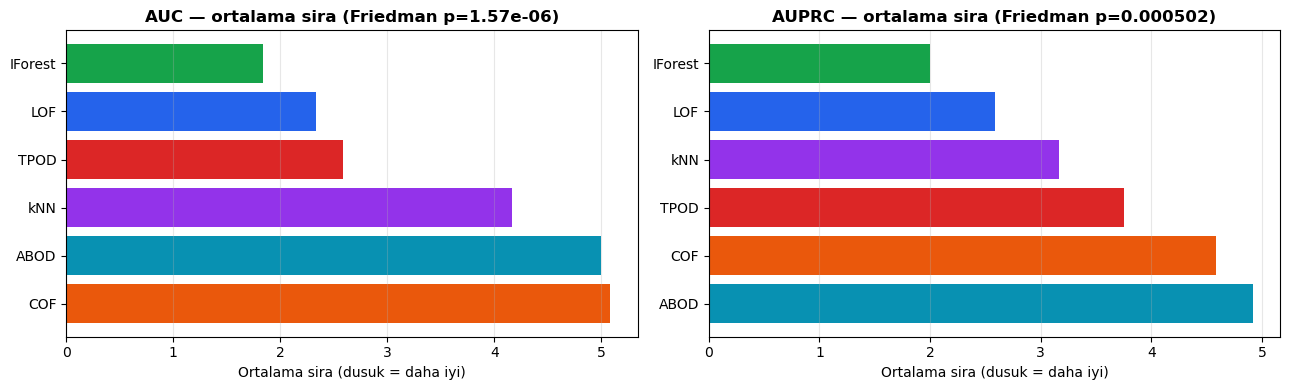

In [8]:
def stats_for(metric):
    m = tables[metric][UNSUP]
    ranks = m.rank(axis=1, ascending=False)
    avg_rank = ranks.mean().sort_values()
    stat, p = friedmanchisquare(*[m[a].values for a in UNSUP])
    rows = []
    for a in UNSUP:
        if a == "TPOD":
            continue
        diff = m["TPOD"] - m[a]
        try:
            _, pw = wilcoxon(m["TPOD"], m[a])
        except ValueError:
            pw = 1.0
        rows.append({"rakip": a, "TPOD kazanir": int((diff > 0).sum()),
                     "TPOD kaybeder": int((diff < 0).sum()),
                     "ort. fark": diff.mean(), "p": pw})
    w = pd.DataFrame(rows).sort_values("p").reset_index(drop=True)
    k = len(w)
    w["p_holm"] = np.minimum(1, np.maximum.accumulate(w["p"] * (k - np.arange(k))))
    w["anlamli (0.05)"] = w["p_holm"] < 0.05
    return avg_rank, stat, p, w

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["AUC", "AUPRC"]):
    avg_rank, stat, p, w = stats_for(metric)
    print("=" * 25 + " " + metric + " " + "=" * 25)
    print("Ortalama siralar (dusuk = iyi):")
    print(avg_rank.round(2).to_string())
    print("Friedman chi2 = " + f"{stat:.3f}" + "   p = " + f"{p:.4g}")
    print("TPOD vs rakipler (Wilcoxon, 12 blok):")
    print(w.round(4).to_string(index=False))
    print()
    ax.barh(avg_rank.index[::-1], avg_rank.values[::-1],
            color=[colors[a] for a in avg_rank.index[::-1]])
    ax.set_title(metric + " — ortalama sira (Friedman p=" + f"{p:.3g}" + ")", fontweight="bold")
    ax.set_xlabel("Ortalama sira (dusuk = daha iyi)")
    ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("tpod_bench_siralar.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. TPOD Hız ve Eşik Analizi

In [9]:
print("Ortalama calisma suresi (sn / ornekleme, n=" + str(N_SAMPLE) + "):")
print(res.groupby("algo")["time"].mean().reindex(ALL_ALGOS).round(3).to_string())
print()
tp = res[res.algo == "TPOD"].groupby(["dataset", "ratio"])[["AUC", "AUPRC", "P@n", "F1"]].mean()
print("TPOD ozet (eta kontaminasyondan, c=0.5):")
print(tp.round(4).to_string())

Ortalama calisma suresi (sn / ornekleme, n=2000):
algo
TPOD              0.916
LOF               0.033
IForest           0.116
kNN               0.015
COF               0.615
ABOD              0.135
RF (gozetimli)    1.933

TPOD ozet (eta kontaminasyondan, c=0.5):
                  AUC   AUPRC     P@n      F1
dataset ratio                                
BAF     0.01   0.5376  0.0161  0.0300  0.0300
        0.02   0.5328  0.0256  0.0225  0.0225
        0.05   0.5445  0.0617  0.0670  0.0670
PaySim  0.01   0.8757  0.1483  0.2200  0.2200
        0.02   0.8228  0.1495  0.2000  0.2000
        0.05   0.7649  0.1569  0.1800  0.1800
Sparkov 0.01   0.7790  0.0761  0.0900  0.0900
        0.02   0.7713  0.0933  0.1150  0.1150
        0.05   0.7941  0.2002  0.2690  0.2690
ULB     0.01   0.9571  0.4393  0.4950  0.4950
        0.02   0.9475  0.4890  0.5375  0.5375
        0.05   0.9388  0.5943  0.6200  0.6200


## 9. Bulgular

**1. Gerçekçi fraud oranında TPOD belirgin şekilde daha iyi.** İlk deneyde (~%33 fraud, grid search) elde edilen AUC değerleri ile bu protokol (sabit parametre, %1–5 fraud) karşılaştırıldığında:

| Veri seti | İlk deney AUC | Benchmark AUC (%1 / %2 / %5) |
|---|---|---|
| ULB | 0.908 | **0.957** / 0.948 / 0.939 |
| PaySim | 0.703 | **0.876** / 0.823 / 0.765 |
| Sparkov | 0.720 | 0.779 / 0.771 / 0.794 |
| BAF | 0.461 | 0.538 / 0.533 / 0.545 |

Bu, TPOD'un "aykırı değer nadirdir" varsayımıyla tutarlıdır: fraud oranı arttıkça dolandırıcılık kayıtları kendi yoğun kümelerini oluşturur ve yoğunluk temelli skor zayıflar. İlk deneydeki düşük sonuçların bir kısmı algoritmadan değil, deney tasarımından kaynaklanmaktadır.

**2. Rakiplerle karşılaştırma (12 blok, Friedman p < 0.001).**
- AUC ortalama sırası: IForest 1.83, LOF 2.33, **TPOD 2.58**, kNN 4.17, ABOD 5.00, COF 5.08.
- TPOD; **ABOD, kNN ve COF'tan anlamlı olarak daha iyi** (Wilcoxon + Holm, p < 0.05), **LOF ile istatistiksel olarak eşdeğer** (6 kazanç / 6 kayıp), **Isolation Forest'tan anlamlı olarak daha kötü** (2 kazanç / 10 kayıp).
- AUPRC'de TPOD 4. sırada; yalnızca IForest ile fark anlamlı.

**3. TPOD'un güçlü olduğu durum: sürekli, ayrışabilir özellikler + kümelenmiş fraud.** ULB'de %1 oranında tüm gözetimsiz yöntemler arasında en yüksek AUC (0.957) TPOD'undur. Fraud oranı %5'e çıktığında LOF (0.949 → 0.665) ve COF (0.903 → 0.496) çökerken TPOD 0.939'da kalmaktadır. Doğal komşuluk ile k'nın veriye göre büyümesi (λ), aykırı kümelerin birbirini "maskelemesine" karşı direnç sağlamaktadır.

**4. TPOD'un zayıf olduğu durumlar.**
- **BAF:** Tüm gözetimsiz yöntemler AUC ≈ 0.52–0.58 bandında; gözetimli RF ise 0.74–0.84. Bu veri setindeki dolandırıcılık, geometrik olarak aykırı değil; sorun TPOD'a özgü değil, gözetimsiz aykırı değer yaklaşımının sınırıdır.
- **PaySim:** Fraud oranı arttıkça TPOD (0.876 → 0.765) LOF'a (0.880 → 0.823) göre daha hızlı düşmektedir.
- **Sparkov:** IForest belirgin üstün (≈0.85 vs 0.78); özellik bazlı (eksen paralel) ayrışan aykırılıklar ağaç tabanlı yöntemlere daha uygundur.
- **Hız:** TPOD en yavaş gözetimsiz yöntem (≈0.92 sn / 2000 kayıt; LOF 0.03 sn). O(n²) bellek/zaman nedeniyle büyük veride örnekleme zorunludur.

**5. Gözetimli üst sınır.** RF tüm bloklarda açık farkla en iyidir (AUC 0.74–0.98). Etiket mevcutsa gözetimli yöntemler tercih edilmeli; TPOD etiket bulunmayan senaryolarda ön eleme aracı olarak konumlandırılmalıdır.

**6. η'nın kontaminasyondan belirlenmesi** etiket kullanmadan çalışır; bu durumda TPOD'un F1 değeri P@n'ye eşittir (eşik tam olarak beklenen fraud sayısını işaretler). İlk deneydeki "F1'i η ile grid search" yaklaşımına gerek kalmamaktadır.

**Bildiri için önerilen ana mesaj:** *TPOD, gerçekçi fraud oranlarında klasik yoğunluk/mesafe tabanlı yöntemlerin (LOF, kNN, COF, ABOD) en az eşdeğeri veya daha iyisidir ve aykırı oranı arttığında LOF/COF'a göre çok daha kararlıdır; ancak Isolation Forest'ı geçememekte ve hesaplama maliyeti daha yüksektir.*
